#### Importing Modules

In [27]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import random
import os
from PIL import Image
import warnings
warnings.filterwarnings('ignore')
import keras 
import tensorflow as tf 
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report,confusion_matrix 
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D,MaxPool2D,Dense,Flatten,GlobalAveragePooling2D,Dropout,BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau,ModelCheckpoint

In [28]:
tf.config.optimizer.set_jit(False)

#### Setting Seed

In [29]:
SEED=42
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

#### Setting Constants

In [30]:
DATASET_DIR=r"/kaggle/input/datasets/alxmamaev/flowers-recognition/flowers"
LABEL_MAP={
    "daisy":0,
    "dandelion":1,
    "rose":2,
    "sunflower":3,
    "tulip":4
}
IMG_SIZE=(224,224)
BATCH_SIZE=32

#### Reading Files

In [31]:
image_paths=[]
labels=[]
for class_name,class_label in LABEL_MAP.items():
    class_path=os.path.join(DATASET_DIR,class_name)
    for file in os.listdir(class_path):
        file_path=os.path.join(class_path,file)
        image_paths.append(file_path)
        labels.append(class_label)
print(f"Sample Image Path: {image_paths[4]} and Label: {labels[4]}")

Sample Image Path: /kaggle/input/datasets/alxmamaev/flowers-recognition/flowers/daisy/34695914906_961f92ffcd_n.jpg and Label: 0


#### Creating DataFrame

In [32]:
df=pd.DataFrame({
    'image':image_paths,
    'label':labels
})
df.head()

,image,label
0,/kaggle/input/datasets/alxmamaev/flowers-recog...,0
1,/kaggle/input/datasets/alxmamaev/flowers-recog...,0
2,/kaggle/input/datasets/alxmamaev/flowers-recog...,0
3,/kaggle/input/datasets/alxmamaev/flowers-recog...,0
4,/kaggle/input/datasets/alxmamaev/flowers-recog...,0


#### Shuffling DataFrame

In [33]:
df=df.sample(frac=1,random_state=SEED)
df.head()

,image,label
3800,/kaggle/input/datasets/alxmamaev/flowers-recog...,4
2014,/kaggle/input/datasets/alxmamaev/flowers-recog...,2
1923,/kaggle/input/datasets/alxmamaev/flowers-recog...,2
2533,/kaggle/input/datasets/alxmamaev/flowers-recog...,2
3747,/kaggle/input/datasets/alxmamaev/flowers-recog...,4


In [34]:
print("Total Number of images:",len(df),"images")

Total Number of images: 4317 images


#### Checking Corrupted Images

In [35]:
valid_images=[]
for image in df['image']:
    try:
        with Image.open(image) as img:
            img.verify()
        valid_images.append(image)
    except Exception:
        print("Invalid Image: ", image)
print(f"Valid Images: {len(valid_images)} out of {len(df)} images.")

Valid Images: 4317 out of 4317 images.


#### Removing invalid Images

In [36]:
df=df[df['image'].isin(valid_images)].reset_index(drop=True)
df.head()

,image,label
0,/kaggle/input/datasets/alxmamaev/flowers-recog...,4
1,/kaggle/input/datasets/alxmamaev/flowers-recog...,2
2,/kaggle/input/datasets/alxmamaev/flowers-recog...,2
3,/kaggle/input/datasets/alxmamaev/flowers-recog...,2
4,/kaggle/input/datasets/alxmamaev/flowers-recog...,4


#### Visualizing Random Images

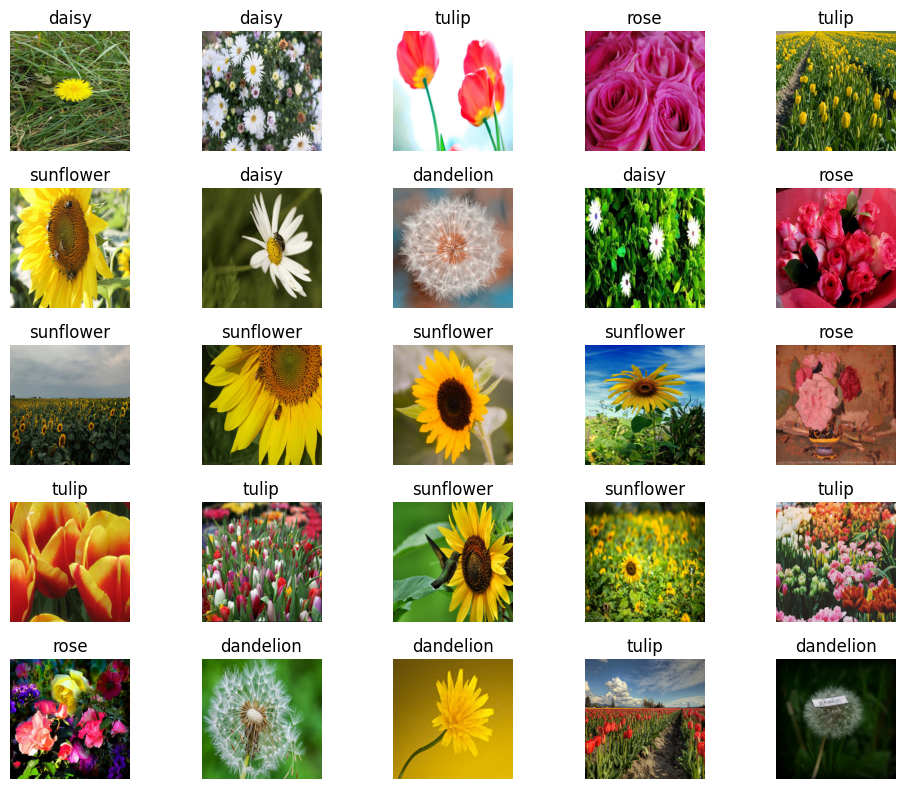

In [37]:
plt.figure(figsize=(10,8))
sample_df=df.sample(25,random_state=SEED)
for i,(_,row) in enumerate(sample_df.iterrows()):
    image_path=row['image']
    label=row['label']
    plt.subplot(5,5,i+1)
    image=Image.open(image_path).convert("RGB").resize(IMG_SIZE)
    plt.imshow(image)
    plt.title({v:k for k,v in LABEL_MAP.items()}[label])
    plt.axis('off')
plt.tight_layout()
plt.show()

#### Fixing Datatypes

In [38]:
df['label']=df['label'].astype(str)
df.head()

,image,label
0,/kaggle/input/datasets/alxmamaev/flowers-recog...,4
1,/kaggle/input/datasets/alxmamaev/flowers-recog...,2
2,/kaggle/input/datasets/alxmamaev/flowers-recog...,2
3,/kaggle/input/datasets/alxmamaev/flowers-recog...,2
4,/kaggle/input/datasets/alxmamaev/flowers-recog...,4


#### Creating Splits

In [39]:
train_df,temp_df=train_test_split(df,test_size=0.3,random_state=SEED,stratify=df['label'])
val_df,test_df=train_test_split(temp_df,test_size=0.5,random_state=SEED,stratify=temp_df['label'])
print(f"Train size: {len(train_df)} images.")
print(f"Val size: {len(val_df)} images.")
print(f"Test size: {len(test_df)} images.")

Train size: 3021 images.
Val size: 648 images.
Test size: 648 images.


#### Creating Generators

In [40]:
train_data_generator=ImageDataGenerator(
    rescale=1.0/255,
    rotation_range=10,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.1,
    shear_range=0.1,
    horizontal_flip=True,
    fill_mode='reflect'
)

In [41]:
val_test_data_generator=ImageDataGenerator(
    rescale=1.0/255,
)

#### Creating Iterators

In [42]:
train_iterator=train_data_generator.flow_from_dataframe(
    train_df,
    x_col='image',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True,
    seed=SEED
)

Found 3021 validated image filenames belonging to 5 classes.


In [43]:
val_iterator=val_test_data_generator.flow_from_dataframe(
    val_df,
    x_col='image',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

Found 648 validated image filenames belonging to 5 classes.


In [44]:
test_iterator=val_test_data_generator.flow_from_dataframe(
    test_df,
    x_col='image',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

Found 648 validated image filenames belonging to 5 classes.


#### Visualizing Images Before and After Augmentation

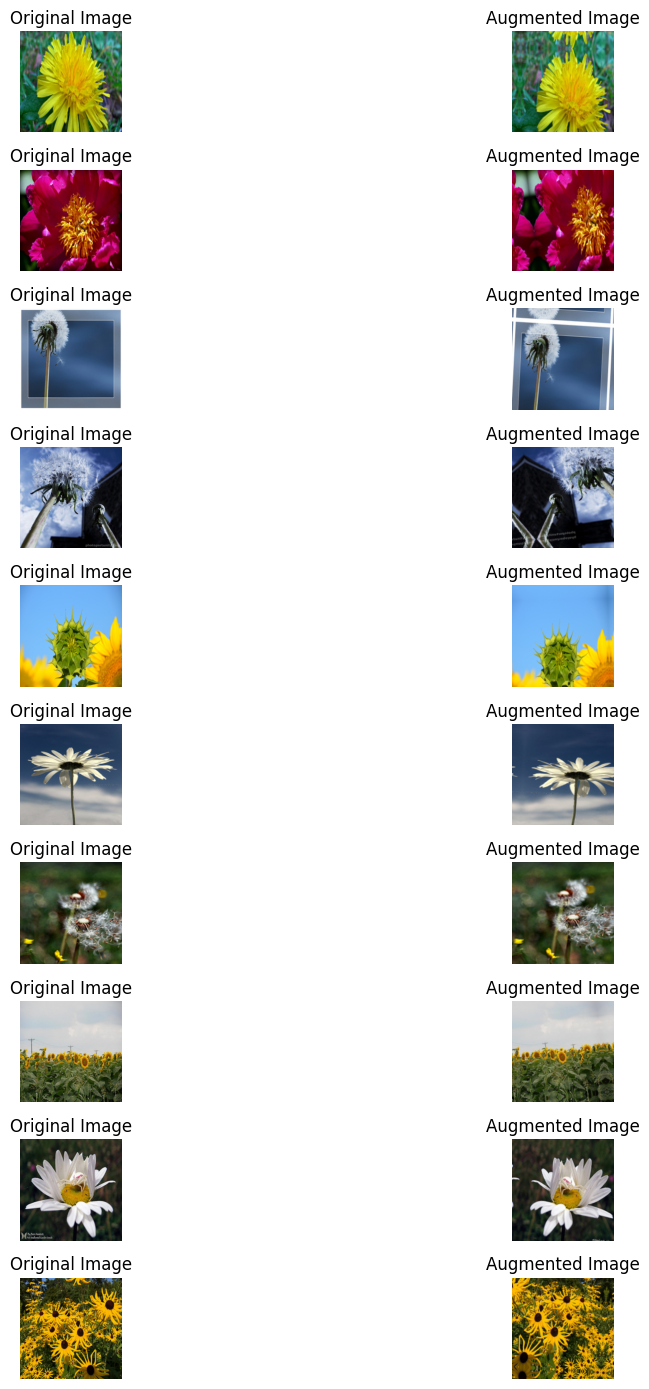

In [64]:
plt.figure(figsize=(14,14))
sample_df2=train_df.sample(10,random_state=SEED)
for i,(_,row) in enumerate(sample_df2.iterrows()):
    image_path=row['image']
    image=Image.open(image_path).convert("RGB").resize(IMG_SIZE)
    image=np.array(image)
    augmented_image=train_data_generator.random_transform(image)    
    plt.subplot(10,2,2*i+1)
    plt.imshow(image)
    plt.axis('off')
    plt.title("Original Image")
    plt.subplot(10,2,2*i+2)
    plt.imshow(augmented_image)
    plt.title("Augmented Image")
    plt.axis('off')
plt.tight_layout()
plt.show()

#### Model

In [46]:
model=Sequential([
    # Layer 1
    Conv2D(64,(3,3),activation='relu',input_shape=(*IMG_SIZE,3)),
    MaxPool2D((2,2)),
    # Layer 2
    Conv2D(128,(3,3),activation='relu'),
    MaxPool2D((3,2)),
    # Layer 3
    Conv2D(256,(3,3),activation='relu'),
    MaxPool2D((2,2)),
    # Layer 4
    Conv2D(512,(3,3),activation='relu'),
    MaxPool2D((2,2)),
    #Layer 5
    Flatten(),
    Dense(512,activation='relu'),
    Dropout(0.4),
    Dense(128,activation='relu'),
    Dropout(0.4),
    Dense(len(LABEL_MAP),activation='softmax')
])

In [47]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 222, 222, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 111, 111, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 109, 109, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 36, 54, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 34, 52, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 17, 26, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 15, 24, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 7, 12, 512)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 43008)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 512)            │    22,020,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,637,893 (90.17 MB)

 Trainable params: 23,637,893 (90.17 MB)

 Non-trainable params: 0 (0.00 B)

In [48]:
opt=keras.optimizers.Adam(learning_rate=5e-4)
model.compile(loss='categorical_crossentropy',optimizer=opt,metrics=['accuracy'])

In [49]:
lr_scheduler=ReduceLROnPlateau(
    monitor='val_loss',
    patience=4,
    factor=0.2,
    min_lr=1e-7
)

In [50]:
early_stop=EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True
)

In [ ]:
checkpoint=ModelCheckpoint(
    "best_cnn_model.keras",
    monitor='val_loss',
    save_best_only=True
)

In [52]:
history=model.fit(train_iterator,epochs=50,validation_data=val_iterator,callbacks=[lr_scheduler,early_stop,checkpoint])

Epoch 1/50
65/95 ━━━━━━━━━━━━━━━━━━━━ 11s 394ms/step - accuracy: 0.2667 - loss: 1.5670

2026-10-10 12:26:09.866117: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-10 12:26:10.030532: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


95/95 ━━━━━━━━━━━━━━━━━━━━ 55s 534ms/step - accuracy: 0.3717 - loss: 1.4201 - val_accuracy: 0.3951 - val_loss: 1.5368 - learning_rate: 5.0000e-04
Epoch 2/50
95/95 ━━━━━━━━━━━━━━━━━━━━ 41s 428ms/step - accuracy: 0.4644 - loss: 1.2349 - val_accuracy: 0.4676 - val_loss: 1.2497 - learning_rate: 5.0000e-04
Epoch 3/50
95/95 ━━━━━━━━━━━━━━━━━━━━ 41s 430ms/step - accuracy: 0.5170 - loss: 1.1481 - val_accuracy: 0.5586 - val_loss: 1.0555 - learning_rate: 5.0000e-04
Epoch 4/50
95/95 ━━━━━━━━━━━━━━━━━━━━ 41s 434ms/step - accuracy: 0.5730 - loss: 1.0720 - val_accuracy: 0.6250 - val_loss: 0.9708 - learning_rate: 5.0000e-04
Epoch 5/50
95/95 ━━━━━━━━━━━━━━━━━━━━ 41s 433ms/step - accuracy: 0.6322 - loss: 0.9786 - val_accuracy: 0.6651 - val_loss: 0.8794 - learning_rate: 5.0000e-04
Epoch 6/50
95/95 ━━━━━━━━━━━━━━━━━━━━ 41s 426ms/step - accuracy: 0.6478 - loss: 0.9119 - val_accuracy: 0.6728 - val_loss: 0.8547 - learning_rate: 5.0000e-04
Epoch 7/50
95/95 ━━━━━━━━━━━━━━━━━━━━ 41s 431ms/step - accuracy: 0.66

#### Evaluating Model on Test Data

In [53]:
test_results=model.evaluate(test_iterator,return_dict=True)
print(test_results)

21/21 ━━━━━━━━━━━━━━━━━━━━ 3s 166ms/step - accuracy: 0.8349 - loss: 0.5607
{'accuracy': 0.834876537322998, 'loss': 0.560701847076416}


#### Accuracy and Loss Curves

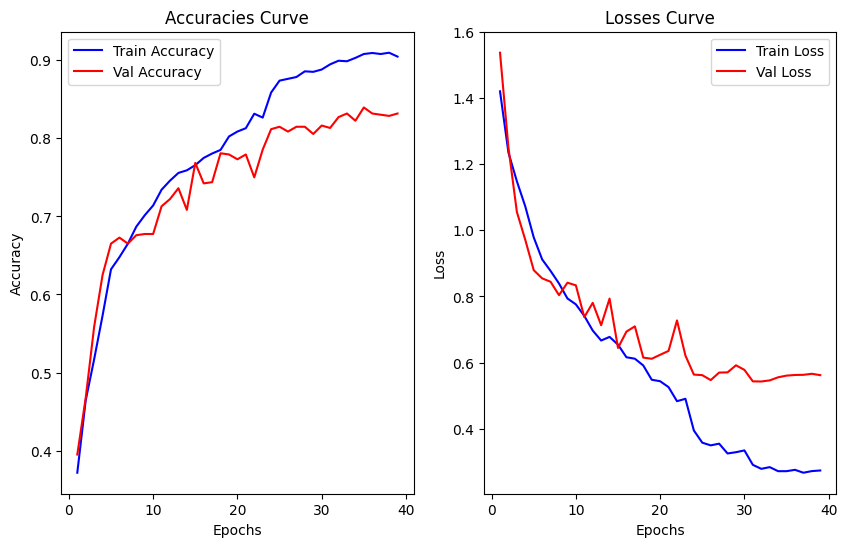

In [54]:
plt.figure(figsize=(10,6))
train_acc=history.history['accuracy']
val_acc=history.history['val_accuracy']
train_loss=history.history['loss']
val_loss=history.history['val_loss']
epochs=range(1,len(train_acc)+1)
plt.subplot(1,2,1)
plt.plot(epochs,train_acc,'b',label="Train Accuracy")
plt.plot(epochs,val_acc,'r',label="Val Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Accuracies Curve")
plt.legend()
plt.subplot(1,2,2)
plt.plot(epochs,train_loss,'b',label="Train Loss")
plt.plot(epochs,val_loss,'r',label="Val Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Losses Curve")
plt.legend()
plt.show()

#### Confusion Matrix

21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 95ms/step


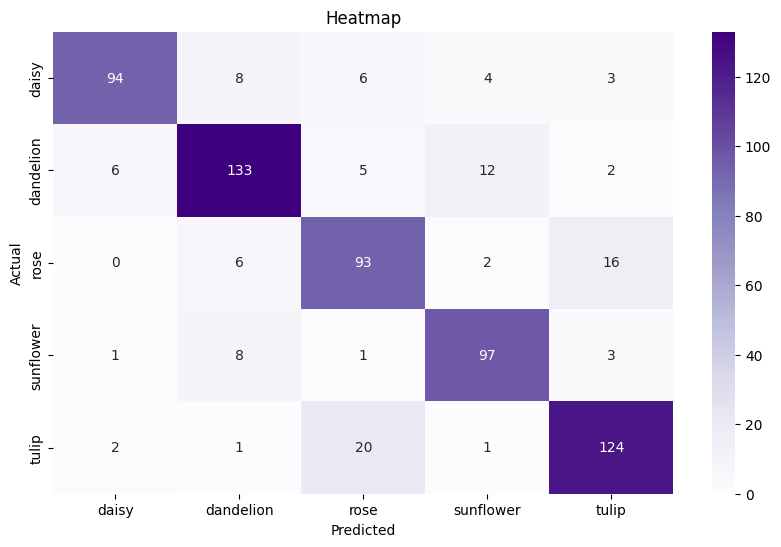

In [55]:
plt.figure(figsize=(10,6))
class_indices = list(range(len(LABEL_MAP)))
class_names = list(LABEL_MAP.keys())
y_true=test_iterator.classes
y_pred=np.argmax(model.predict(test_iterator),axis=1)
cm=confusion_matrix(y_true,y_pred,labels=class_indices)
sns.heatmap(cm,annot=True,fmt='d',cmap="Purples",xticklabels=class_names,yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Heatmap")
plt.show()

#### Classification Report

In [56]:
print(classification_report(y_true,y_pred,labels=class_indices,target_names=class_names))

              precision    recall  f1-score   support

       daisy       0.91      0.82      0.86       115
   dandelion       0.85      0.84      0.85       158
        rose       0.74      0.79      0.77       117
   sunflower       0.84      0.88      0.86       110
       tulip       0.84      0.84      0.84       148

    accuracy                           0.83       648
   macro avg       0.84      0.83      0.83       648
weighted avg       0.84      0.83      0.84       648



#### Visualizing Random Sample

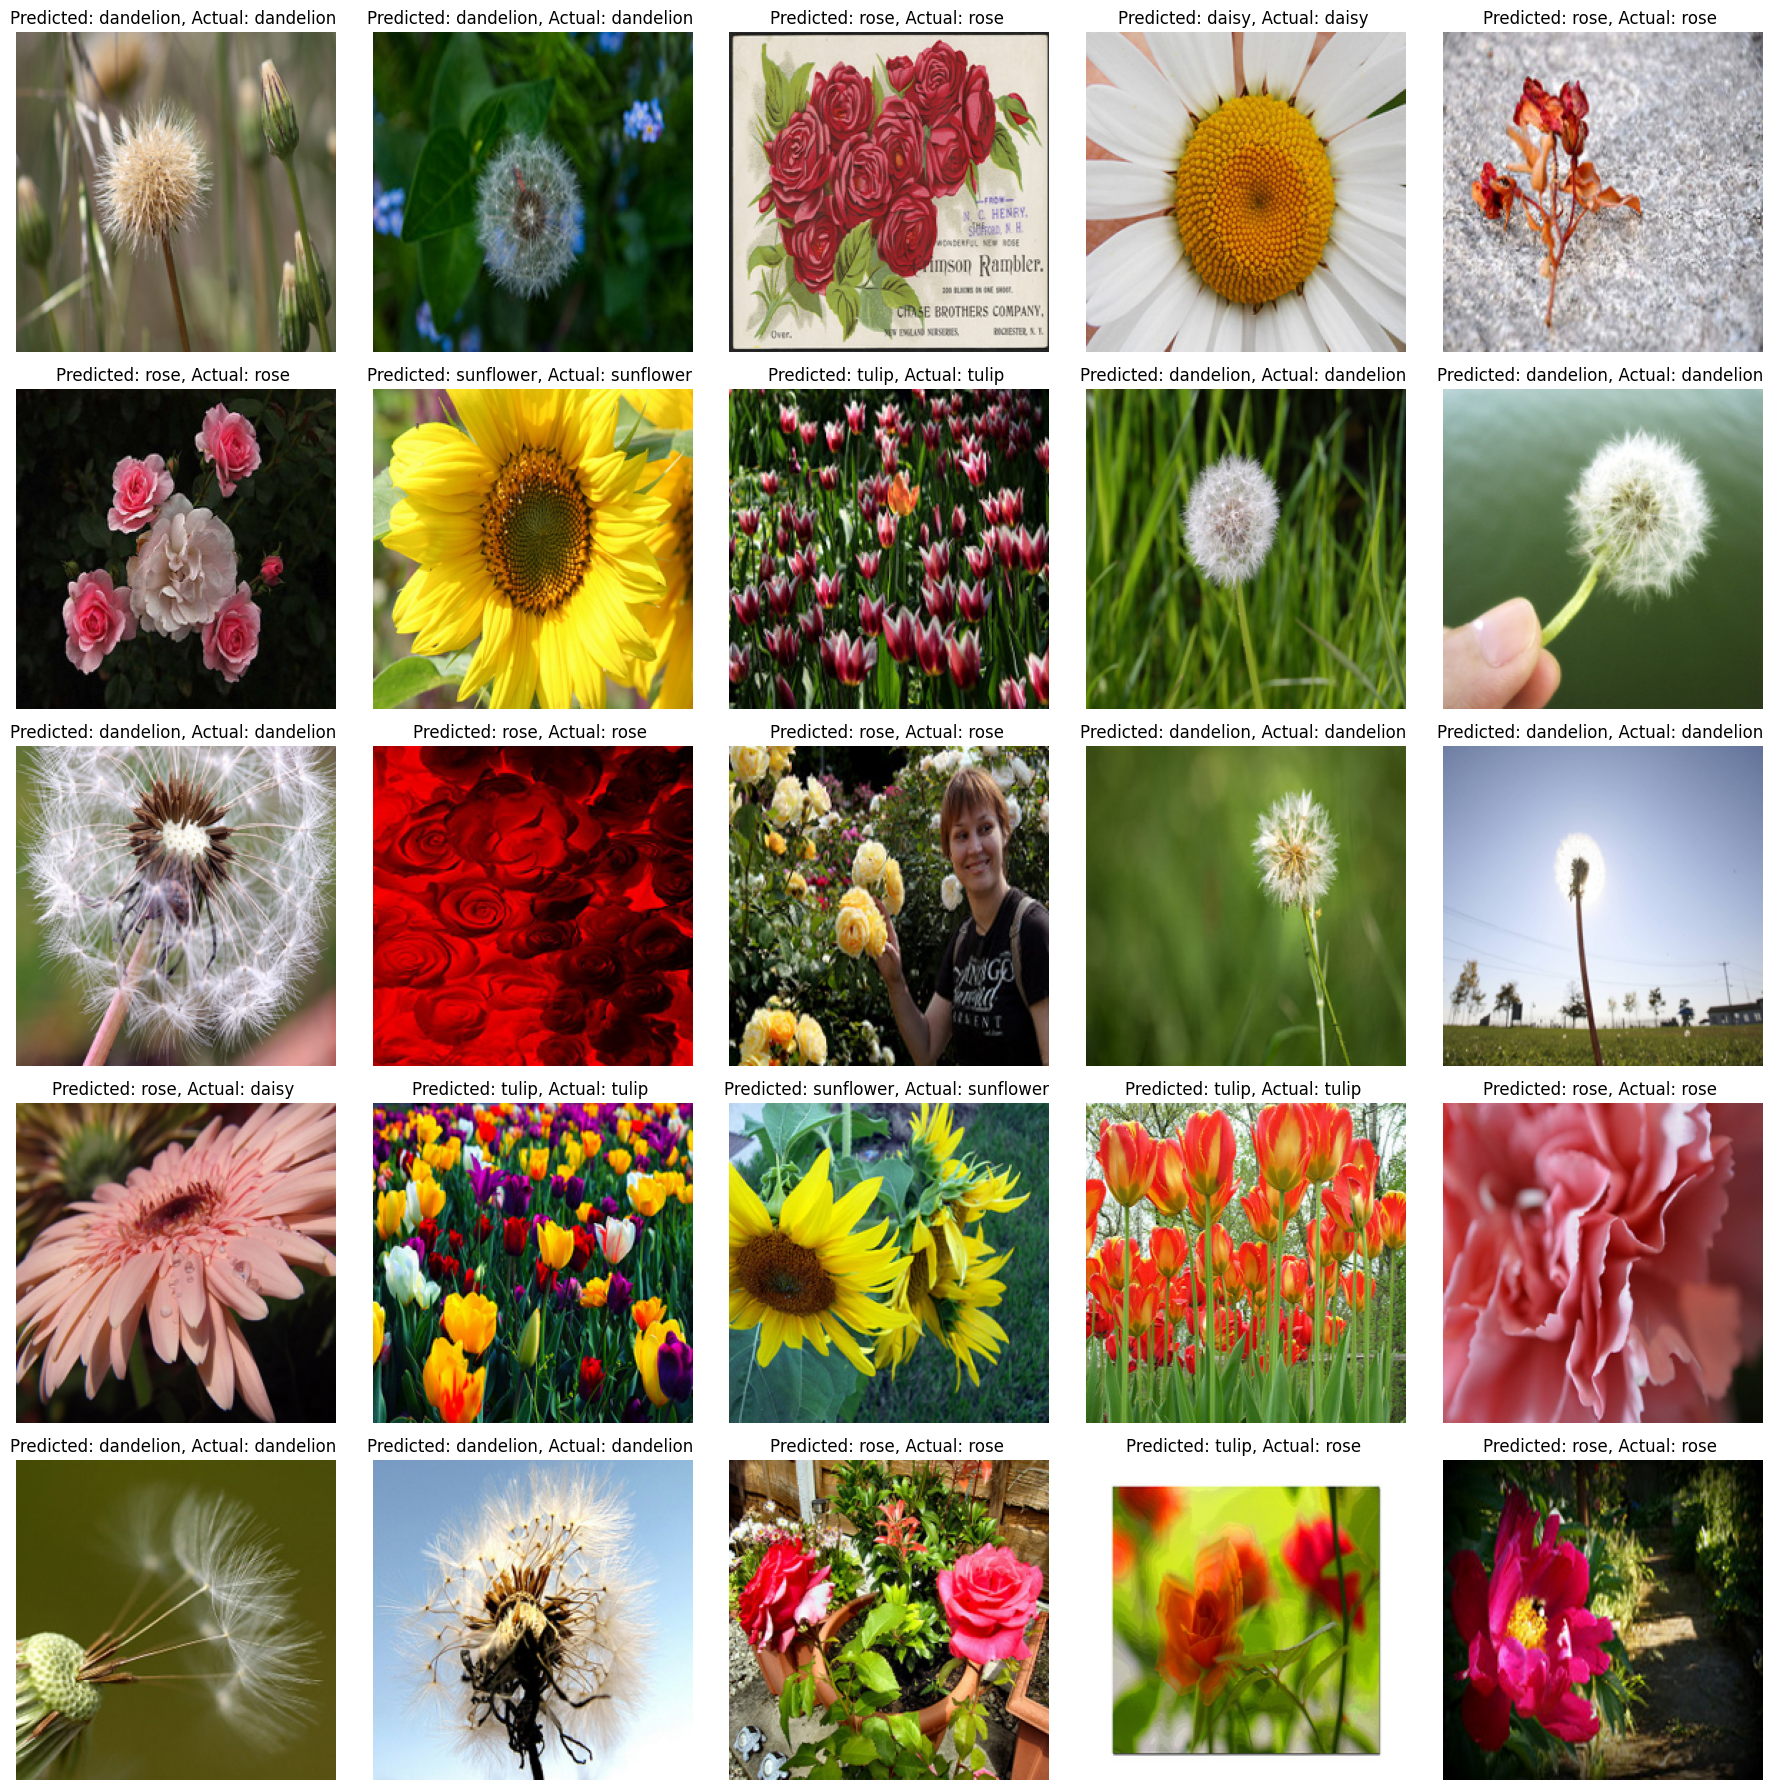

In [60]:
plt.figure(figsize=(18,18))
sample_df=test_df.sample(25,random_state=SEED)
for i,(_,row) in enumerate(sample_df.iterrows()):
    image_path=row['image']
    true_label=row['label']
    plt.subplot(5,5,i+1)
    image=Image.open(image_path).convert("RGB").resize(IMG_SIZE)
    plt.imshow(image)
    image=np.array(image,dtype=np.float32)
    image=image/255.0
    image=np.expand_dims(image,axis=0)
    pred=model.predict(image,verbose=0)
    pred=np.argmax(pred[0])
    idx_to_class = {v: k for k, v in LABEL_MAP.items()}
    plt.title( f"Predicted: {idx_to_class[pred]}, Actual: {idx_to_class[int(true_label)]} ")
    plt.axis('off')
plt.tight_layout()
plt.show()